# Experiment 16 — Recursive feature elimination for the AutoGluon ensemble

Start with the Exp 9 best feature set plus every remaining feature produced by `RentalPreprocessor`, including latitude, longitude, region, lease age, proximity counts, COE fields, and stock fields. Each RFE round fits a fresh AutoGluon GBM + CatBoost ensemble, measures permutation importance on the latest chronological outer-validation period, and removes the weakest features. The outer period directly selects the final feature subset because it is closest to the test horizon; test labels remain reporting-only.

In [9]:
from pathlib import Path
import json
import os
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from autogluon.tabular import TabularPredictor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

configured_root = os.environ.get('KDDM_PROJECT_ROOT')
roots = ([Path(configured_root)] if configured_root else []) + [Path.cwd(), *Path.cwd().parents]
project_root = next(
    (root for root in roots if (root / 'exploration' / 'metul' / 'preprocessing.py').exists()),
    None,
)
if project_root is None:
    raise FileNotFoundError('Set KDDM_PROJECT_ROOT to the project directory.')
sys.path.insert(0, str(project_root / 'exploration' / 'metul'))

# Reuse the audited Exp 9 target and nearest-location feature definitions.
source_notebook = json.loads(
    (project_root / 'exploration' / 'metul' / 'exp_14_resale_features_lgbm.ipynb').read_text()
)
source_cells = {
    cell.get('metadata', {}).get('id'): ''.join(cell.get('source', []))
    for cell in source_notebook['cells']
}
exec(source_cells['setup'], globals())
exec(source_cells['exp9-best-feature-transformer'], globals())

RANDOM_STATE = 42
RFE_TIME_LIMIT = int(os.environ.get('EXP16_RFE_TIME_LIMIT', '180'))
FINAL_TIME_LIMIT = int(os.environ.get('EXP16_FINAL_TIME_LIMIT', '600'))
IMPORTANCE_TIME_LIMIT = int(os.environ.get('EXP16_IMPORTANCE_TIME_LIMIT', '180'))
RFE_DROP_FRACTION = float(os.environ.get('EXP16_DROP_FRACTION', '0.20'))
RFE_MIN_FEATURES = int(os.environ.get('EXP16_MIN_FEATURES', '10'))
RFE_MAX_ROUNDS = int(os.environ.get('EXP16_MAX_ROUNDS', '10'))
RUN_ID = os.environ.get('EXP16_RUN_ID', pd.Timestamp.now().strftime('%Y%m%d_%H%M%S'))
HYPERPARAMETERS = {'GBM': {}, 'CAT': {}}
output_root = project_root / 'exploration' / 'metul' / 'ag_exp_16_rfe' / RUN_ID
print(f'Experiment output: {output_root}')

Experiment output: /Users/metul/Desktop/KDDM-project/exploration/metul/ag_exp_16_rfe/20261016_195400


In [10]:
_, datasets = load_datasets(project_root / 'data')
raw = datasets['train'].copy()
raw['period'] = pd.to_datetime(
    raw['RENT_APPROVAL_DATE'] + '-01'
).dt.to_period('M')

periods = np.sort(raw['period'].unique())
outer_cutoff = periods[int(len(periods) * 0.80)]
raw_rfe_train = raw.loc[raw['period'] < outer_cutoff].copy()
raw_rfe_valid = raw.loc[raw['period'] >= outer_cutoff].copy()

split_summary = pd.DataFrame([
    {
        'partition': 'RFE training',
        'role': 'fit every candidate AutoGluon ensemble',
        'rows': len(raw_rfe_train),
        'first_period': raw_rfe_train.period.min(),
        'last_period': raw_rfe_train.period.max(),
    },
    {
        'partition': 'outer selection validation',
        'role': 'permutation importance and final subset selection',
        'rows': len(raw_rfe_valid),
        'first_period': raw_rfe_valid.period.min(),
        'last_period': raw_rfe_valid.period.max(),
    },
])
display(split_summary)
print(
    'The outer period is intentionally a feature-selection set in this experiment; '
    'it is not an untouched final validation set.'
)

,partition,role,rows,first_period,last_period
0,RFE training,fit every candidate AutoGluon ensemble,117988,2021-01,2024-04
1,outer selection validation,permutation importance and final subset selection,32012,2024-05,2025-03


The outer period is intentionally a feature-selection set in this experiment; it is not an untouched final validation set.


In [11]:
def make_exp16_features(raw_history, raw_future):
    """Return Exp 9 best features followed by every remaining preprocessed feature."""
    preprocessor = RentalPreprocessor(datasets)
    history_base = preprocessor.fit_transform(
        raw_history.drop(columns=['period', TARGET], errors='ignore')
    )
    future_base = preprocessor.transform(
        raw_future.drop(columns=['period', TARGET], errors='ignore')
    )
    history_best, future_best = make_exp9_best_features(
        raw_history, raw_future, history_base, future_base
    )
    remaining_base_features = [
        column for column in history_base.columns if column not in BEST_FEATURES
    ]
    candidate_features = BEST_FEATURES + remaining_base_features
    history_expanded = pd.concat([
        history_best.reset_index(drop=True),
        history_base[remaining_base_features].reset_index(drop=True),
    ], axis=1)
    future_expanded = pd.concat([
        future_best.reset_index(drop=True),
        future_base[remaining_base_features].reset_index(drop=True),
    ], axis=1)
    assert list(history_expanded.columns) == candidate_features
    assert list(future_expanded.columns) == candidate_features
    assert history_expanded.columns.is_unique and future_expanded.columns.is_unique
    return history_expanded, future_expanded, candidate_features

rfe_train_x, rfe_valid_x, candidate_features = make_exp16_features(
    raw_rfe_train, raw_rfe_valid
)
rfe_train_y = raw_rfe_train[TARGET].astype(float).reset_index(drop=True)
rfe_valid_y = raw_rfe_valid[TARGET].astype(float).reset_index(drop=True)
feature_inventory = pd.DataFrame({
    'feature': candidate_features,
    'in_exp9_best_set': [feature in BEST_FEATURES for feature in candidate_features],
    'dtype': [str(rfe_train_x[feature].dtype) for feature in candidate_features],
    'train_missing': [int(rfe_train_x[feature].isna().sum()) for feature in candidate_features],
    'validation_missing': [int(rfe_valid_x[feature].isna().sum()) for feature in candidate_features],
})
print(f'Candidate features: {len(candidate_features)}; Exp 9 best: {len(BEST_FEATURES)}; added: {len(candidate_features) - len(BEST_FEATURES)}')
display(feature_inventory)

[categorical_clean] HDB lookup | TOWN: 26 -> 26 unique values | lowercase, trim, collapse whitespace, and replace hyphen/underscore/slash separators with spaces
[categorical_clean] HDB lookup | BLOCK: 2735 -> 2735 unique values | lowercase, trim, collapse whitespace, and replace hyphen/underscore/slash separators with spaces
[categorical_clean] HDB lookup | STREET: 576 -> 576 unique values | lowercase, trim, collapse whitespace, and replace hyphen/underscore/slash separators with spaces
[categorical_clean] HDB lookup | POSTAL_CODE: 9180 -> 9180 unique values | lowercase, trim, collapse whitespace, and replace hyphen/underscore/slash separators with spaces
[categorical_clean] HDB lookup | SUBZONE: 156 -> 156 unique values | lowercase, trim, collapse whitespace, and replace hyphen/underscore/slash separators with spaces
[categorical_clean] HDB lookup | PLANNING_AREA: 31 -> 31 unique values | lowercase, trim, collapse whitespace, and replace hyphen/underscore/slash separators with spaces


,feature,in_exp9_best_set,dtype,train_missing,validation_missing
0,TOWN,True,string,0,0
1,BLOCK,True,string,0,0
2,STREET,True,string,0,0
3,FLAT_TYPE,True,string,0,0
4,FLAT_MODEL,True,string,0,0
5,FLOOR_AREA_SQM,True,float64,0,0
6,approval_date_num,True,int64,0,0
7,approval_month,True,int64,0,0
8,coe_quota_premium_mean,True,float64,0,0
9,YEAR_COMPLETED,True,int64,0,0


In [12]:
def fit_autogluon_ensemble(train_x, train_y, features, path, time_limit):
    train_data = train_x[features].copy()
    train_data[TARGET] = train_y.to_numpy()
    return TabularPredictor(
        label=TARGET,
        problem_type='regression',
        eval_metric='root_mean_squared_error',
        path=str(path),
    ).fit(
        train_data=train_data,
        hyperparameters=HYPERPARAMETERS,
        presets=['medium_quality', 'ignore_text'],
        time_limit=time_limit,
        verbosity=2,
    )

def regression_metrics(actual, prediction):
    return {
        'RMSE': mean_squared_error(actual, prediction) ** 0.5,
        'MAE': mean_absolute_error(actual, prediction),
        'R2': r2_score(actual, prediction),
    }

In [13]:
current_features = candidate_features.copy()
rfe_rows = []
importance_parts = []

for round_number in range(1, RFE_MAX_ROUNDS + 1):
    print(
        f'RFE round {round_number}: fitting {len(current_features)} features '
        'and evaluating on the outer selection period'
    )
    predictor = fit_autogluon_ensemble(
        rfe_train_x,
        rfe_train_y,
        current_features,
        output_root / f'rfe_round_{round_number}_{len(current_features)}_features',
        RFE_TIME_LIMIT,
    )
    prediction = predictor.predict(rfe_valid_x[current_features]).astype(float).to_numpy()
    metrics = regression_metrics(rfe_valid_y, prediction)
    rfe_rows.append({
        'round': round_number,
        'feature_count': len(current_features),
        **metrics,
        'features': current_features.copy(),
        'best_model': predictor.model_best,
    })

    importance_data = rfe_valid_x[current_features].copy()
    importance_data[TARGET] = rfe_valid_y.to_numpy()
    importance = predictor.feature_importance(
        data=importance_data,
        model=predictor.model_best,
        features=current_features,
        feature_stage='original',
        subsample_size=min(10_000, len(importance_data)),
        time_limit=IMPORTANCE_TIME_LIMIT,
        num_shuffle_sets=3,
        silent=False,
    )
    importance_scores = importance['importance'].reindex(current_features).fillna(-np.inf)
    round_importance = importance_scores.rename('importance').reset_index()
    round_importance = round_importance.rename(columns={'index': 'feature'})
    round_importance['round'] = round_number
    round_importance['feature_count'] = len(current_features)
    importance_parts.append(round_importance)

    if len(current_features) <= RFE_MIN_FEATURES:
        break
    remove_count = max(1, int(np.ceil(len(current_features) * RFE_DROP_FRACTION)))
    remove_count = min(remove_count, len(current_features) - RFE_MIN_FEATURES)
    removed_features = importance_scores.sort_values().head(remove_count).index.tolist()
    print(f'Removing {remove_count} weakest features: {removed_features}')
    current_features = [
        feature for feature in current_features if feature not in removed_features
    ]

rfe_results = pd.DataFrame(rfe_rows)
rfe_importance_history = pd.concat(importance_parts, ignore_index=True)
best_rfe_index = rfe_results['RMSE'].idxmin()
selected_features = list(rfe_results.loc[best_rfe_index, 'features'])
display(rfe_results.drop(columns='features').sort_values('RMSE'))
print(
    f'Selected RFE round {int(rfe_results.loc[best_rfe_index, "round"])} '
    f'with {len(selected_features)} features using outer-period RMSE.'
)
print(selected_features)

Verbosity: 2 (Standard Logging)
=================== System Info ===================
AutoGluon Version:  1.6.2
Python Version:     3.12.14
Operating System:   Darwin
Platform Machine:   arm64
Platform Version:   Darwin Kernel Version 25.6.0: Fri Jul 31 19:16:20 PDT 2026; root:xnu-12377.161.14~5/RELEASE_ARM64_T8142
CPU Count:          10
Pytorch Version:    2.10.0
CUDA Version:       CUDA is not available
GPU Count:          WARNING: Exception was raised when calculating GPU count (AssertionError)
Memory Avail:       3.92 GB / 16.00 GB (24.5%)
Disk Space Avail:   167.02 GB / 460.38 GB (36.3%)
Presets specified: ['medium_quality', 'ignore_text']
Beginning AutoGluon training ... Time limit = 180s
AutoGluon will save models to "/Users/metul/Desktop/KDDM-project/exploration/metul/ag_exp_16_rfe/20261016_195400/rfe_round_1_36_features"
Train Data Rows:    117988
Train Data Columns: 36
Label Column:       MONTHLY_RENT
Problem Type:       regression
Preprocessing data...
Using Feature Generators

RFE round 1: fitting 36 features and evaluating on the outer selection period


	Stage 1 Generators:
		Fitting AsTypeFeatureGenerator...
	Stage 2 Generators:
		Fitting FillNaFeatureGenerator...
	Stage 3 Generators:
		Fitting IdentityFeatureGenerator...
		Fitting CategoryFeatureGenerator...
			Fitting CategoryMemoryMinimizeFeatureGenerator...
		Fitting DatetimeFeatureGenerator...
	Stage 4 Generators:
		Fitting DropUniqueFeatureGenerator...
	Stage 5 Generators:
		Fitting DropDuplicatesFeatureGenerator...
	Types of features in original data (raw dtype, special dtypes):
		('float', [])                      : 12 | ['FLOOR_AREA_SQM', 'coe_quota_premium_mean', 'mrt_dist_nearest_km', 'mall_dist_nearest_km', 'monthly_target_lag', ...]
		('int', [])                        : 14 | ['approval_date_num', 'approval_month', 'YEAR_COMPLETED', 'MAX_FLOOR', 'LEASE_COMMENCE_DATE', ...]
		('object', [])                     :  8 | ['TOWN', 'BLOCK', 'STREET', 'FLAT_TYPE', 'FLAT_MODEL', ...]
		('object', ['datetime_as_object']) :  1 | ['RENT_APPROVAL_DATE']
		('object', ['text'])        

Removing 8 weakest features: ['nearest_tourist_attraction_name', 'REGION', 'coe_bids_mean', 'RENT_APPROVAL_DATE', 'approval_year', 'approval_date_num', 'monthly_target_lag', 'nearest_monument_name']
RFE round 2: fitting 28 features and evaluating on the outer selection period


	Stage 2 Generators:
		Fitting FillNaFeatureGenerator...
	Stage 3 Generators:
		Fitting IdentityFeatureGenerator...
		Fitting CategoryFeatureGenerator...
			Fitting CategoryMemoryMinimizeFeatureGenerator...
	Stage 4 Generators:
		Fitting DropUniqueFeatureGenerator...
	Stage 5 Generators:
		Fitting DropDuplicatesFeatureGenerator...
	Types of features in original data (raw dtype, special dtypes):
		('float', [])        : 10 | ['FLOOR_AREA_SQM', 'coe_quota_premium_mean', 'mrt_dist_nearest_km', 'mall_dist_nearest_km', 'town_flat_type_target_mean', ...]
		('int', [])          : 12 | ['approval_month', 'YEAR_COMPLETED', 'MAX_FLOOR', 'LEASE_COMMENCE_DATE', 'lease_age', ...]
		('object', [])       :  5 | ['TOWN', 'BLOCK', 'STREET', 'FLAT_TYPE', 'FLAT_MODEL']
		('object', ['text']) :  1 | ['nearest_mrt_name']
	Types of features in processed data (raw dtype, special dtypes):
		('category', [])                   :  5 | ['TOWN', 'BLOCK', 'STREET', 'FLAT_TYPE', 'FLAT_MODEL']
		('category', ['text_a

...

	Stage 3 Generators:
		Fitting IdentityFeatureGenerator...
		Fitting CategoryFeatureGenerator...
			Fitting CategoryMemoryMinimizeFeatureGenerator...
	Stage 4 Generators:
		Fitting DropUniqueFeatureGenerator...
	Stage 5 Generators:
		Fitting DropDuplicatesFeatureGenerator...
	Types of features in original data (raw dtype, special dtypes):
		('float', [])  : 6 | ['FLOOR_AREA_SQM', 'mrt_dist_nearest_km', 'town_flat_type_target_mean', 'LATITUDE', 'LONGITUDE', ...]
		('int', [])    : 2 | ['YEAR_COMPLETED', 'LEASE_COMMENCE_DATE']
		('object', []) : 5 | ['TOWN', 'BLOCK', 'STREET', 'FLAT_TYPE', 'FLAT_MODEL']
	Types of features in processed data (raw dtype, special dtypes):
		('category', []) : 5 | ['TOWN', 'BLOCK', 'STREET', 'FLAT_TYPE', 'FLAT_MODEL']
		('float', [])    : 6 | ['FLOOR_AREA_SQM', 'mrt_dist_nearest_km', 'town_flat_type_target_mean', 'LATITUDE', 'LONGITUDE', ...]
		('int', [])      : 2 | ['YEAR_COMPLETED', 'LEASE_COMMENCE_DATE']
	0.2s = Fit runtime
	13 features in original data u

Removing 3 weakest features: ['LONGITUDE', 'FLAT_MODEL', 'stock_volume_mean']
RFE round 6: fitting 10 features and evaluating on the outer selection period


			Fitting CategoryMemoryMinimizeFeatureGenerator...
	Stage 4 Generators:
		Fitting DropUniqueFeatureGenerator...
	Stage 5 Generators:
		Fitting DropDuplicatesFeatureGenerator...
	Types of features in original data (raw dtype, special dtypes):
		('float', [])  : 4 | ['FLOOR_AREA_SQM', 'mrt_dist_nearest_km', 'town_flat_type_target_mean', 'LATITUDE']
		('int', [])    : 2 | ['YEAR_COMPLETED', 'LEASE_COMMENCE_DATE']
		('object', []) : 4 | ['TOWN', 'BLOCK', 'STREET', 'FLAT_TYPE']
	Types of features in processed data (raw dtype, special dtypes):
		('category', []) : 4 | ['TOWN', 'BLOCK', 'STREET', 'FLAT_TYPE']
		('float', [])    : 4 | ['FLOOR_AREA_SQM', 'mrt_dist_nearest_km', 'town_flat_type_target_mean', 'LATITUDE']
		('int', [])      : 2 | ['YEAR_COMPLETED', 'LEASE_COMMENCE_DATE']
	0.2s = Fit runtime
	10 features in original data used to generate 10 features in processed data.
	Train Data (Processed) Memory Usage: 6.08 MB (0.1% of available memory)
Data preprocessing and feature engineerin

,round,feature_count,RMSE,MAE,R2,best_model
0,1,36,468.920991,344.700755,0.490577,WeightedEnsemble_L2
5,6,10,469.079877,342.015542,0.490231,WeightedEnsemble_L2
1,2,28,483.652421,367.246708,0.458066,WeightedEnsemble_L2
4,5,13,511.896769,391.026819,0.392922,WeightedEnsemble_L2
2,3,22,512.978739,391.730295,0.390353,WeightedEnsemble_L2
3,4,17,515.645957,394.462752,0.383997,WeightedEnsemble_L2


Selected RFE round 1 with 36 features using outer-period RMSE.
['TOWN', 'BLOCK', 'STREET', 'FLAT_TYPE', 'FLAT_MODEL', 'FLOOR_AREA_SQM', 'approval_date_num', 'approval_month', 'coe_quota_premium_mean', 'YEAR_COMPLETED', 'MAX_FLOOR', 'mrt_dist_nearest_km', 'mall_dist_nearest_km', 'monthly_target_lag', 'town_flat_type_target_mean', 'nearest_mrt_name', 'nearest_tourist_attraction_name', 'nearest_monument_name', 'RENT_APPROVAL_DATE', 'LEASE_COMMENCE_DATE', 'approval_year', 'lease_age', 'flat_type_num', 'LATITUDE', 'LONGITUDE', 'REGION', 'mrt_within_1km', 'mrt_within_2km', 'mall_within_1km', 'mall_within_2km', 'school_dist_nearest_km', 'school_within_1km', 'school_within_2km', 'coe_bids_mean', 'stock_close_mean', 'stock_volume_mean']


,feature,importance,round,feature_count
14,town_flat_type_target_mean,85.915535,1,36
3,FLAT_TYPE,21.451753,1,36
5,FLOOR_AREA_SQM,18.354686,1,36
23,LATITUDE,10.280305,1,36
2,STREET,6.899818,1,36
11,mrt_dist_nearest_km,6.228708,1,36
1,BLOCK,4.112750,1,36
24,LONGITUDE,3.196829,1,36
9,YEAR_COMPLETED,3.025334,1,36
0,TOWN,2.899599,1,36


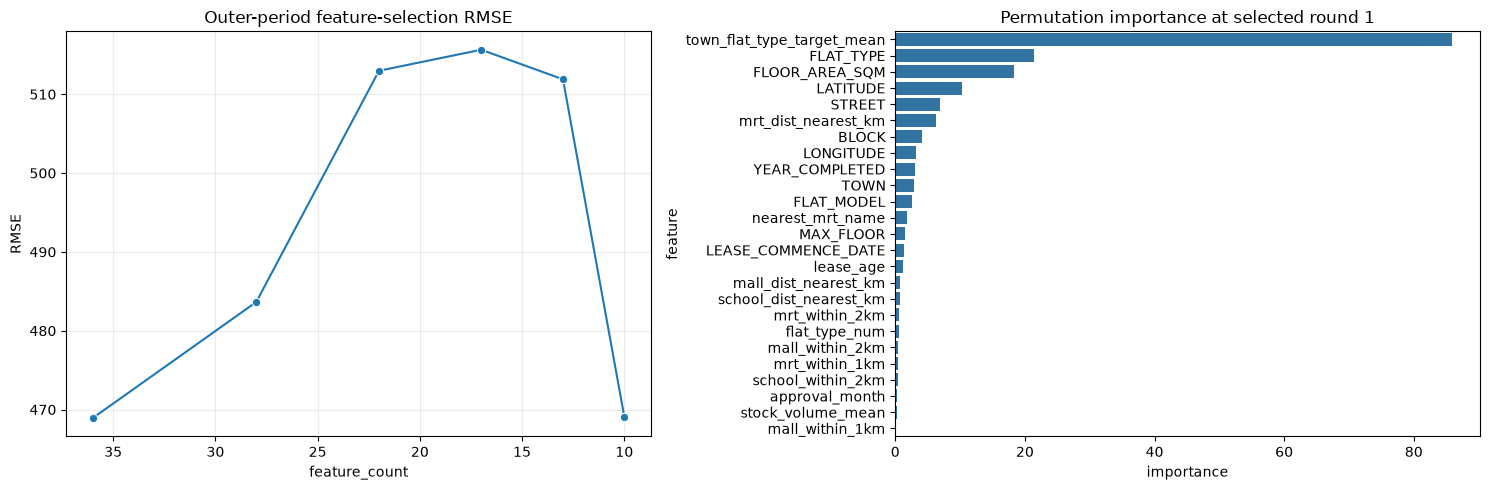

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.lineplot(data=rfe_results, x='feature_count', y='RMSE', marker='o', ax=axes[0])
axes[0].invert_xaxis()
axes[0].set_title('Outer-period feature-selection RMSE')
axes[0].grid(alpha=0.25)

selected_round = int(rfe_results.loc[best_rfe_index, 'round'])
selected_importance = (
    rfe_importance_history.loc[lambda frame: frame['round'].eq(selected_round)]
    .replace(-np.inf, np.nan)
    .sort_values('importance', ascending=False)
)
sns.barplot(
    data=selected_importance.head(25),
    x='importance',
    y='feature',
    ax=axes[1],
)
axes[1].set_title(f'Permutation importance at selected round {selected_round}')
plt.tight_layout()
display(selected_importance)

In [15]:
# The outer period has already evaluated every RFE candidate above.
outer_selection_results = (
    rfe_results.drop(columns='features')
    .sort_values('RMSE')
    .reset_index(drop=True)
)
display(outer_selection_results)
print(
    f'Outer-period selection chose round '
    f'{int(rfe_results.loc[best_rfe_index, "round"])} with '
    f'{len(selected_features)} features and RMSE '
    f'{rfe_results.loc[best_rfe_index, "RMSE"]:.6f}.'
)
print(
    'This score is used for feature selection and must not be described as an '
    'untouched estimate of final generalization.'
)

,round,feature_count,RMSE,MAE,R2,best_model
0,1,36,468.920991,344.700755,0.490577,WeightedEnsemble_L2
1,6,10,469.079877,342.015542,0.490231,WeightedEnsemble_L2
2,2,28,483.652421,367.246708,0.458066,WeightedEnsemble_L2
3,5,13,511.896769,391.026819,0.392922,WeightedEnsemble_L2
4,3,22,512.978739,391.730295,0.390353,WeightedEnsemble_L2
5,4,17,515.645957,394.462752,0.383997,WeightedEnsemble_L2


Outer-period selection chose round 1 with 36 features and RMSE 468.920991.
This score is used for feature selection and must not be described as an untouched estimate of final generalization.
